In [2]:
# Tail-latency setup for tail-data.db (same schema as 00_tail_latency.ipynb)
import sqlite3
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

cnx_tail = sqlite3.connect('../data/tail-data_1w.db')

# Optional comparison DB (used in later comparison cell)
cnx_base = sqlite3.connect('../data.db')

print('Connected: tail-data.db and data.db')

Connected: tail-data.db and data_copy.db


In [4]:
# Tail impact per platform with multiple tail definitions
# tail_impact (%) = (full_mean - trimmed_mean) / trimmed_mean * 100
# Here we define the "tail" cutoff as p99, p99.9, and p99.99 (per provider).

from __future__ import annotations

from dataclasses import dataclass


@dataclass(frozen=True)
class ProviderQuerySpec:
    provider: str
    source: str  # 'base' or 'tail'
    experiment: str


def _load_provider_samples(spec: ProviderQuerySpec) -> np.ndarray:
    if spec.source == "tail":
        df = pd.read_sql_query(
            """
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = ?
            """,
            cnx_tail,
            params=[spec.provider, spec.experiment],
        )
    else:
        if spec.experiment == "warmstart" and spec.provider != "fastly":
            df = pd.read_sql_query(
                """
                SELECT http_req_waiting
                FROM data
                WHERE provider = ?
                  AND experiment = 'warmstart'
                  AND cold_starts = 0
                """,
                cnx_base,
                params=[spec.provider],
            )
        else:
            df = pd.read_sql_query(
                """
                SELECT http_req_waiting
                FROM data
                WHERE provider = ?
                  AND experiment = ?
                """,
                cnx_base,
                params=[spec.provider, spec.experiment],
            )

    if df.empty:
        return np.array([])

    s = pd.to_numeric(df["http_req_waiting"], errors="coerce").dropna()
    # Guard against zeros/negatives (log plots elsewhere assume positive)
    s = s[s > 0]
    return s.to_numpy()


def _tail_impact_wide_table(
    specs: list[ProviderQuerySpec],
    quantiles: list[float],
) -> pd.DataFrame:
    """One row per provider, with tail impact columns for each quantile cutoff."""

    def q_label(q: float) -> str:
        # Use stable, human-readable names.
        if abs(q - 0.99) < 1e-12:
            return "p99"
        if abs(q - 0.999) < 1e-12:
            return "p99_9"
        if abs(q - 0.9999) < 1e-12:
            return "p99_99"
        # Fallback: p{quantile*100} with '.' -> '_'
        return f"p{q * 100:.4f}".rstrip("0").rstrip(".").replace(".", "_")

    rows: list[dict[str, float | int | str]] = []

    for spec in specs:
        samples = _load_provider_samples(spec)
        if samples.size == 0:
            continue

        full_mean = float(np.mean(samples))
        row: dict[str, float | int | str] = {
            "provider": spec.provider,
            "source": spec.source,
            "experiment": spec.experiment,
            "n": int(samples.size),
            "full_mean": full_mean,
        }

        for q in quantiles:
            label = q_label(q)
            cutoff = float(np.quantile(samples, q))
            trimmed = samples[samples <= cutoff]
            trimmed_mean = float(np.mean(trimmed)) if trimmed.size else float("nan")

            impact_pct = (
                (full_mean - trimmed_mean) / trimmed_mean * 100.0
                if np.isfinite(trimmed_mean) and trimmed_mean != 0.0
                else float("nan")
            )

            row[f"{label}_cutoff"] = cutoff
            row[f"{label}_trimmed_mean"] = trimmed_mean
            row[f"{label}_tail_impact_pct"] = impact_pct

        rows.append(row)

    df_out = pd.DataFrame(rows)
    if df_out.empty:
        return df_out

    # Sort by the strongest (p99.99) impact if present, else p99.9, else p99.
    sort_key = (
        "p99_99_tail_impact_pct"
        if "p99_99_tail_impact_pct" in df_out.columns
        else ("p99_9_tail_impact_pct" if "p99_9_tail_impact_pct" in df_out.columns else "p99_tail_impact_pct")
    )
    return df_out.sort_values(sort_key, ascending=False).reset_index(drop=True)


def _df_to_markdown(df: pd.DataFrame) -> str:
    def fmt(v) -> str:
        if v is None or (isinstance(v, float) and not np.isfinite(v)):
            return ""
        if isinstance(v, (int, np.integer)):
            return str(int(v))
        if isinstance(v, (float, np.floating)):
            return f"{float(v):.3f}"
        return str(v)

    cols = list(df.columns)
    header = "| " + " | ".join(cols) + " |"
    sep = "| " + " | ".join(["---"] * len(cols)) + " |"
    lines = [header, sep]
    for row in df.itertuples(index=False):
        lines.append("| " + " | ".join(fmt(getattr(row, c)) for c in cols) + " |")
    return "\n".join(lines)


base_providers = [
    "google",
    "awsX86",
    "awsARM",
    "oracleX86",
    "oracleARM",
    "deno",
    "cloudflare",
    "flyio",
    "fastly",
]

specs = [ProviderQuerySpec(p, "base", "warmstart") for p in base_providers]
# EC2 instance comes from tail DB
specs.append(ProviderQuerySpec("awsEC2", "tail", "warmstart"))

quantiles = [0.99, 0.999, 0.9999]
impact = _tail_impact_wide_table(specs, quantiles=quantiles)

if impact.empty:
    print("No data found for requested providers.")
else:
    impact_display = impact.copy()

    float_cols = [c for c in impact_display.columns if c not in {"provider", "source", "experiment", "n"}]
    for c in float_cols:
        impact_display[c] = pd.to_numeric(impact_display[c], errors="coerce")

    # Means/cutoffs: 3 decimals, impacts: 2 decimals
    for c in impact_display.columns:
        if c.endswith("_tail_impact_pct"):
            impact_display[c] = impact_display[c].round(2)
        elif c.endswith("_cutoff") or c.endswith("_trimmed_mean") or c == "full_mean":
            impact_display[c] = impact_display[c].round(3)

    print(impact_display.to_string(index=False))
    print("\nMarkdown table:\n")
    print(_df_to_markdown(impact_display))


  provider source experiment       n  full_mean  p99_cutoff  p99_trimmed_mean  p99_tail_impact_pct  p99_9_cutoff  p99_9_trimmed_mean  p99_9_tail_impact_pct  p99_99_cutoff  p99_99_trimmed_mean  p99_99_tail_impact_pct
     flyio   base  warmstart 1873464      9.131      23.274             7.040                29.71       110.934               7.466                  22.31       6514.622                8.091                   12.86
 oracleARM   base  warmstart 1886056     66.003     798.093            50.867                29.76      1530.112              60.054                   9.91      12822.131               62.483                    5.63
      deno   base  warmstart  293177     17.064      53.099            12.858                32.72      1257.224              14.542                  17.34       3850.375               16.401                    4.04
    fastly   base  warmstart  640105     11.247      45.143             9.732                15.57       338.570              10.456    

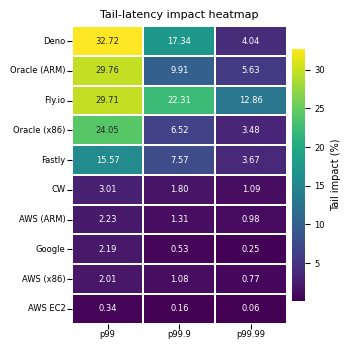

In [5]:
# Heatmap: tail-impact (%) per provider and percentile cutoff (p99 / p99.9 / p99.99)
import seaborn as sns
import matplotlib.pyplot as plt

# Paper-friendly styling (ACM-ish sizing, 1-column figure)
plt.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 8,
    'axes.labelsize': 7,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
})

impact_cols = ["p99_tail_impact_pct", "p99_9_tail_impact_pct", "p99_99_tail_impact_pct"]

provider_name = {
    "deno": "Deno",
    "oracleARM": "Oracle (ARM)",
    "oracleX86": "Oracle (x86)",
    "flyio": "Fly.io",
    "fastly": "Fastly",
    "cloudflare": "CW",
    "awsARM": "AWS (ARM)",
    "awsX86": "AWS (x86)",
    "google": "Google",
    "awsEC2": "AWS EC2",
}

col_name = {
    "p99_tail_impact_pct": "p99",
    "p99_9_tail_impact_pct": "p99.9",
    "p99_99_tail_impact_pct": "p99.99",
}

if "impact" not in globals() or impact is None or impact.empty:
    print("No impact table available (run the previous cell first).")
else:
    missing = [c for c in impact_cols if c not in impact.columns]
    if missing:
        raise KeyError(f"Missing expected impact columns: {missing}. Available: {list(impact.columns)}")

    heat_df = impact[["provider"] + impact_cols].copy()
    for c in impact_cols:
        heat_df[c] = pd.to_numeric(heat_df[c], errors="coerce")
    heat_df = heat_df.dropna(subset=impact_cols, how="all")

    # Sort like the LaTeX table: descending p99 impact (then p99.9, then p99.99).
    heat_df = heat_df.sort_values(impact_cols, ascending=[False, False, False]).reset_index(drop=True)
    heat_df["provider"] = heat_df["provider"].map(lambda p: provider_name.get(p, p))

    heat_pivot = heat_df.set_index("provider")[impact_cols].rename(columns=col_name)

    # ACM one-column width is ~3.33in; height scales with number of providers.
    fig_w = 3.33
    fig_h = 3.33
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    sns.heatmap(
        heat_pivot,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 6},
        cmap="viridis",
        linewidths=0.35,
        linecolor="white",
        cbar_kws={"label": "Tail impact (%)", "shrink": 0.85, "pad": 0.02},
        ax=ax,
    )
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("Tail-latency impact heatmap")
    ax.tick_params(axis="x", rotation=0, pad=1)
    ax.tick_params(axis="y", rotation=0, pad=1)

    fig.tight_layout(pad=0.2)
    fig.savefig("../figures/tail-impact-factor.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

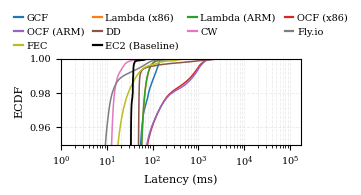

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Comparison tail view: old providers (warmstart) + awsEC2 from tail-data.db
providers = [
    'google', 'awsX86', 'awsARM', 'oracleX86', 'oracleARM',
    'deno', 'cloudflare', 'flyio', 'fastly'
]
experiment = 'warmstart'
tail_provider = 'awsEC2'
tail_experiment = 'warmstart'

# Paper-friendly styling (ACM-ish sizing, 1-column figure)
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'lines.linewidth': 1.2,
})

x_log_base = 10
x_min = 1
x_max = None
y_min = 0.95
y_max = 1.0

provider_label = {
    'deno': 'DD',
    'oracleARM': 'OCF (ARM)',
    'oracleX86': 'OCF (x86)',
    'flyio': 'Fly.io',
    'fastly': 'FEC',
    'cloudflare': 'CW',
    'awsARM': 'Lambda (ARM)',
    'awsX86': 'Lambda (x86)',
    'google': 'GCF',
    'awsEC2': 'EC2 (Baseline)',
}

def load_latencies_base(provider: str, experiment: str) -> np.ndarray:
    if experiment == 'warmstart' and provider != 'fastly':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        '''
        params = [provider]
    elif experiment == 'warmstart' and provider == 'fastly':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        '''
        params = [provider]
    elif experiment == 'coldstart':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        '''
        params = [provider]
    else:
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = ?
        '''
        params = [provider, experiment]

    try:
        df = pd.read_sql_query(query, cnx_base, params=params)
    except Exception:
        return np.array([])
    return pd.to_numeric(df['http_req_waiting'], errors='coerce').dropna().values

def load_latencies_tail(provider: str, experiment: str) -> np.ndarray:
    query = '''
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = ?
    '''
    params = [provider, experiment]

    df = pd.read_sql_query(query, cnx_tail, params=params)
    return pd.to_numeric(df['http_req_waiting'], errors='coerce').dropna().values

palette = sns.color_palette('tab10', n_colors=len(providers))

# One-column ACM width is ~3.33in
fig, ax = plt.subplots(figsize=(3.33, 2.5))

legend_providers = []
legend_colors = []

for provider, color in zip(providers, palette):
    lat = load_latencies_base(provider, experiment)
    if lat.size == 0:
        continue

    legend_providers.append(provider_label.get(provider, provider))
    legend_colors.append(color)
    sns.ecdfplot(lat, color=color, linewidth=1.1, ax=ax)

lat_tail = load_latencies_tail(tail_provider, tail_experiment)
if lat_tail.size == 0:
    print(f'No latency data for provider {tail_provider} ({tail_experiment}).')
else:
    tail_color = 'black'
    legend_providers.append(provider_label.get(tail_provider, tail_provider))
    legend_colors.append(tail_color)
    sns.ecdfplot(lat_tail, color=tail_color, linewidth=1.3, ax=ax)

ax.set_xlabel('Latency (ms)')
ax.set_ylabel('ECDF')
ax.set_xscale('log', base=x_log_base)
if x_min is not None or x_max is not None:
    ax.set_xlim(left=x_min, right=x_max)
ax.set_ylim(bottom=y_min, top=y_max)
ax.grid(True, which='both', linestyle='--', alpha=0.25, linewidth=0.6)

# Three-row legend above the plot, reading left-to-right
if legend_providers:
    legend_handles = [Line2D([0], [0], color=color, lw=1.6) for color in legend_colors]
    
    # 1. Force exactly 3 rows and calculate columns
    nrows = 3
    ncol = int(np.ceil(len(legend_providers) / nrows))
    
    # 2. Pad lists with empty items so we have a perfect nrows x ncol grid
    pad_size = (nrows * ncol) - len(legend_providers)
    padded_handles = legend_handles + [Line2D([], [], linestyle='none')] * pad_size
    padded_labels = legend_providers + [''] * pad_size
    
    # 3. Transpose from row-major (left-to-right) to column-major (top-to-bottom)
    # This tricks Matplotlib into displaying them left-to-right visually.
    reordered_handles = []
    reordered_labels = []
    for i in range(ncol):
        for j in range(nrows):
            idx = j * ncol + i  # Calculate row-major index mapping
            reordered_handles.append(padded_handles[idx])
            reordered_labels.append(padded_labels[idx])

    ax.legend(
        reordered_handles,
        reordered_labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 1.05), # Shifted slightly up for 3 rows
        ncol=ncol,
        frameon=False,
        handlelength=0.9,
        columnspacing=0.9,
        handletextpad=0.4,
        borderaxespad=0.0,
    )

# Leave extra headroom for a 3-row legend (top margin lowered from 0.82 to 0.74)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.74), pad=0.2)
fig.savefig('../figures/tail-all-ecdf.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)

In [25]:
# Table: median / p95 / p99 / p99.9 / p99.99 per platform (incl. AWS EC2)
# + Tail Factor (TF) per percentile: pXX / p50
# Uses the same provider lists + load_latencies_* functions as the ECDF figure cell above.

import numpy as np
import pandas as pd

# Expect these from the previous cell; fall back to the default values used there.
experiment = globals().get("experiment", "warmstart")
tail_provider = globals().get("tail_provider", "awsEC2")
tail_experiment = globals().get("tail_experiment", "warmstart")
providers = globals().get(
    "providers",
    ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"],
)
provider_label = globals().get("provider_label", {})

quantiles = [0.50, 0.95, 0.99, 0.999, 0.9999]
quantile_cols = ["median", "p95", "p99", "p99.9", "p99.99"]

rows = []

# Base providers (data.db)
for p in providers:
    if "load_latencies_base" not in globals():
        raise NameError("load_latencies_base is not defined. Run the ECDF figure cell above first.")

    lat = load_latencies_base(p, experiment)
    lat = pd.to_numeric(pd.Series(lat), errors="coerce").dropna().to_numpy(dtype=float)
    lat = lat[lat > 0]
    if lat.size == 0:
        continue

    qs = np.quantile(lat, quantiles)
    rows.append(
        {
            "platform": provider_label.get(p, p),
            "provider": p,
            "source": "base",
            "experiment": experiment,
            "n": int(lat.size),
            **{k: float(v) for k, v in zip(quantile_cols, qs)},
        }
    )

# Tail provider (tail-data_1w.db)
if "load_latencies_tail" not in globals():
    raise NameError("load_latencies_tail is not defined. Run the ECDF figure cell above first.")

lat_tail = load_latencies_tail(tail_provider, tail_experiment)
lat_tail = pd.to_numeric(pd.Series(lat_tail), errors="coerce").dropna().to_numpy(dtype=float)
lat_tail = lat_tail[lat_tail > 0]
if lat_tail.size:
    qs = np.quantile(lat_tail, quantiles)
    rows.append(
        {
            "platform": provider_label.get(tail_provider, tail_provider),
            "provider": tail_provider,
            "source": "tail",
            "experiment": tail_experiment,
            "n": int(lat_tail.size),
            **{k: float(v) for k, v in zip(quantile_cols, qs)},
        }
    )

summary = pd.DataFrame(rows)
if summary.empty:
    print("No data available to summarize (table is empty).")
else:
    # Paper-friendly ordering: same as plot, then EC2
    ordered = [*providers, tail_provider]
    summary["_order"] = summary["provider"].apply(lambda x: ordered.index(x) if x in ordered else 10**9)
    summary = summary.sort_values(["_order", "provider"]).drop(columns=["_order"]).reset_index(drop=True)

    # Tail Factor (TF): pXX / p50
    for pcol in ["p95", "p99", "p99.9", "p99.99"]:
        tf_col = f"tf_{pcol}"
        summary[tf_col] = summary[pcol] / summary["median"]

    display_cols = [
        "platform",
        "n",
        "median",
        "p95",
        "tf_p95",
        "p99",
        "tf_p99",
        "p99.9",
        "tf_p99.9",
        "p99.99",
        "tf_p99.99",
    ]

    out = summary[display_cols].copy()

    for c in ["median", "p95", "p99", "p99.9", "p99.99"]:
        out[c] = out[c].map(lambda v: f"{float(v):.3f}")
    for c in ["tf_p95", "tf_p99", "tf_p99.9", "tf_p99.99"]:
        out[c] = out[c].map(lambda v: f"{float(v):.3f}")

    print(out.to_string(index=False))


    platform       n median    p95 tf_p95     p99 tf_p99    p99.9 tf_p99.9    p99.99 tf_p99.99
      Google 1919356 42.526 55.075  1.295 110.091  2.589  151.310    3.558   275.797     6.485
   AWS (x86) 1618744 43.999 58.180  1.322  77.831  1.769  139.696    3.175   525.331    11.940
   AWS (ARM) 1915505 43.842 58.102  1.325  77.418  1.766  137.627    3.139   566.438    12.920
Oracle (x86) 1848286 44.771 77.659  1.735 726.871 16.235 1475.457   32.956  5330.732   119.067
Oracle (ARM) 1886056 42.846 75.392  1.760 798.093 18.627 1530.112   35.712 12822.131   299.258
        Deno  293177  9.080 49.335  5.433  53.099  5.848 1257.224  138.461  3850.375   424.049
  Cloudflare  278482  9.656 12.762  1.322  17.636  1.827   38.541    3.992   254.244    26.331
      Fly.io 1873464  6.875  9.339  1.358  23.274  3.385  110.934   16.135  6514.622   947.515
      Fastly  640105  8.941 17.562  1.964  45.143  5.049  338.570   37.866  1016.669   113.705
     AWS EC2   64020 32.403 33.736  1.041  37.764 

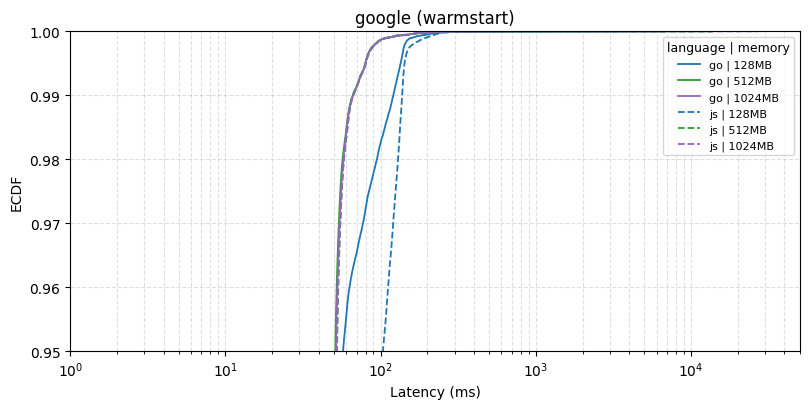

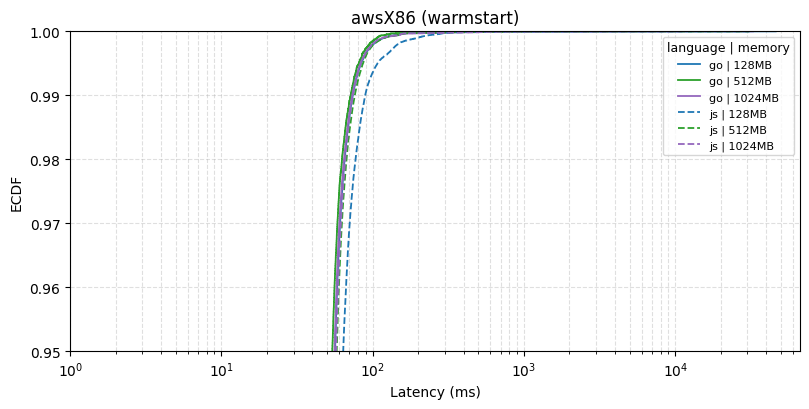

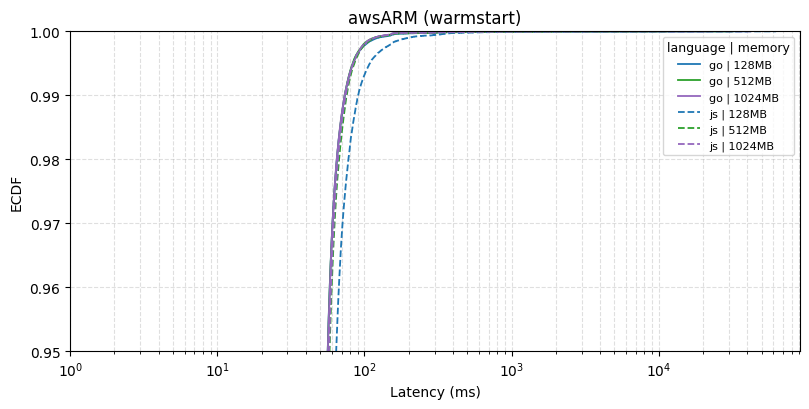

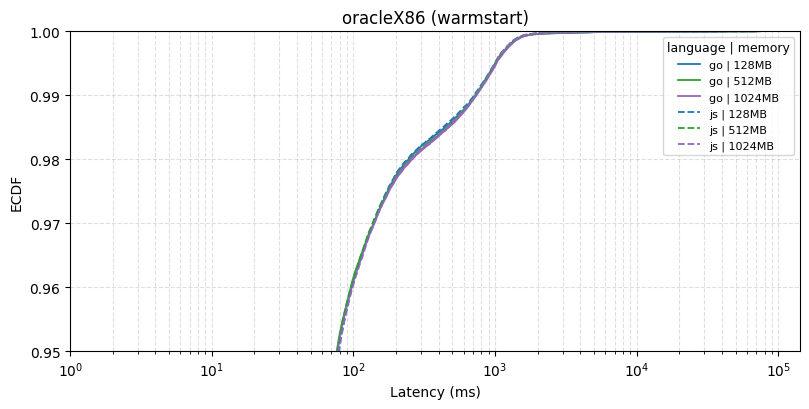

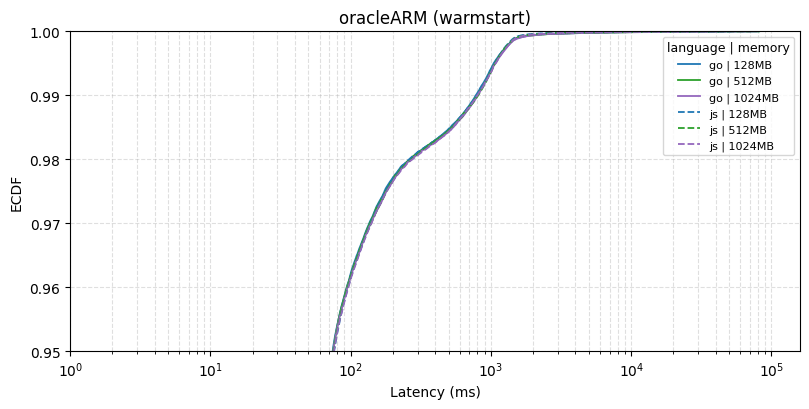

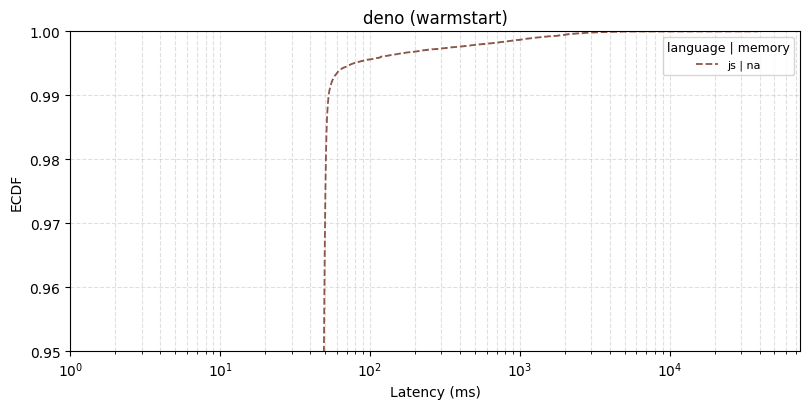

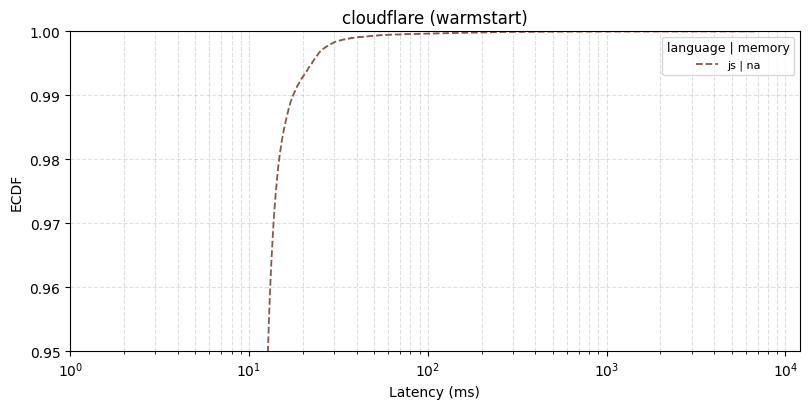

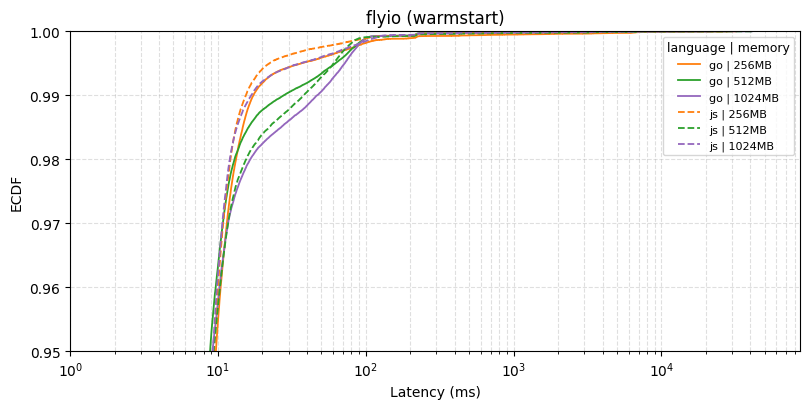

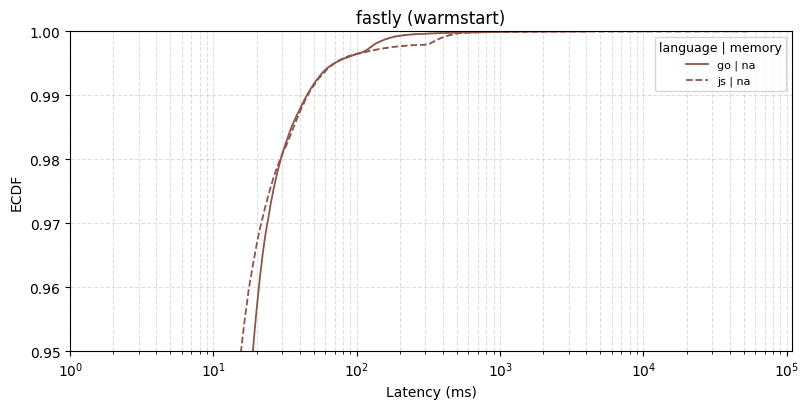

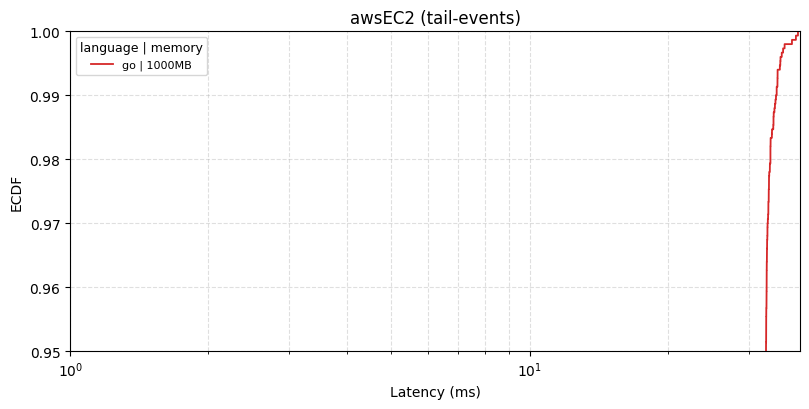

In [8]:
# Comparison tail view by provider: separate ECDF figure per provider, split by language+memory
import re
from itertools import cycle

providers = [
    'google', 'awsX86', 'awsARM', 'oracleX86', 'oracleARM',
    'deno', 'cloudflare', 'flyio', 'fastly'
]
experiment = 'warmstart'
tail_provider = 'awsEC2'
tail_experiment = 'tail-events'

x_log_base = 10
x_min = 1
x_max = None
y_min = 0.95
y_max = 1.0

def memory_sort_key(memory_value: str) -> tuple[int, str]:
    match = re.search(r'\d+', str(memory_value))
    if match:
        return (int(match.group()), str(memory_value))
    return (10**9, str(memory_value))

def load_latencies_base_frame(provider: str, experiment: str) -> pd.DataFrame:
    if experiment == 'warmstart' and provider != 'fastly':
        query = '''
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        '''
        params = [provider]
    elif experiment == 'warmstart' and provider == 'fastly':
        query = '''
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        '''
        params = [provider]
    elif experiment == 'coldstart':
        query = '''
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        '''
        params = [provider]
    else:
        query = '''
            SELECT language, memory, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = ?
        '''
        params = [provider, experiment]

    try:
        df = pd.read_sql_query(query, cnx_base, params=params)
    except Exception:
        return pd.DataFrame(columns=['language', 'memory', 'http_req_waiting'])

    if df.empty:
        return df

    df['http_req_waiting'] = pd.to_numeric(df['http_req_waiting'], errors='coerce')
    df = df.dropna(subset=['http_req_waiting', 'language', 'memory'])
    if df.empty:
        return df

    df['language'] = df['language'].astype(str).str.lower()
    df['memory'] = df['memory'].astype(str)
    return df

def load_latencies_tail_frame(provider: str, experiment: str) -> pd.DataFrame:
    query = '''
        SELECT language, memory, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = ?
    '''
    df = pd.read_sql_query(query, cnx_tail, params=[provider, experiment])
    if df.empty:
        return df

    df['http_req_waiting'] = pd.to_numeric(df['http_req_waiting'], errors='coerce')
    df = df.dropna(subset=['http_req_waiting', 'language', 'memory'])
    if df.empty:
        return df

    df['language'] = df['language'].astype(str).str.lower()
    df['memory'] = df['memory'].astype(str)
    return df

provider_frames = {}
for provider in providers:
    dfp = load_latencies_base_frame(provider, experiment)
    if not dfp.empty:
        provider_frames[provider] = dfp

df_tail = load_latencies_tail_frame(tail_provider, tail_experiment)
if not df_tail.empty:
    provider_frames[tail_provider] = df_tail

if not provider_frames:
    print('No provider data available for comparison plot.')
else:
    all_languages = sorted({lang for dfp in provider_frames.values() for lang in dfp['language'].unique()})
    all_memories = sorted({mem for dfp in provider_frames.values() for mem in dfp['memory'].unique()}, key=memory_sort_key)

    linestyle_candidates = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 2))]
    linestyle_map = {}
    style_cycle = cycle(linestyle_candidates)
    for lang in all_languages:
        linestyle_map[lang] = next(style_cycle)

    memory_palette = sns.color_palette('tab10', n_colors=max(1, len(all_memories)))
    memory_color_map = {mem: color for mem, color in zip(all_memories, memory_palette)}

    for provider, dfp in provider_frames.items():
        configs = sorted(
            {(row.language, row.memory) for row in dfp[['language', 'memory']].itertuples(index=False)},
            key=lambda x: (x[0], memory_sort_key(x[1]))
        )

        if not configs:
            continue

        fig, ax = plt.subplots(figsize=(8.2, 4.2))

        for language, memory in configs:
            lat = dfp[(dfp['language'] == language) & (dfp['memory'] == memory)]['http_req_waiting'].to_numpy()
            if lat.size == 0:
                continue
            sns.ecdfplot(
                lat,
                color=memory_color_map[memory],
                linestyle=linestyle_map[language],
                linewidth=1.3,
                ax=ax,
                label=f'{language} | {memory}',
            )

        subtitle = f'{provider} ({tail_experiment})' if provider == tail_provider else f'{provider} ({experiment})'
        ax.set_title(subtitle)
        ax.set_xlabel('Latency (ms)')
        ax.set_ylabel('ECDF')
        ax.set_xscale('log', base=x_log_base)
        if x_min is not None or x_max is not None:
            ax.set_xlim(left=x_min, right=x_max)
        ax.set_ylim(bottom=y_min, top=y_max)
        ax.grid(True, which='both', linestyle='--', alpha=0.4)
        ax.legend(title='language | memory', fontsize=8, title_fontsize=9, frameon=True)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

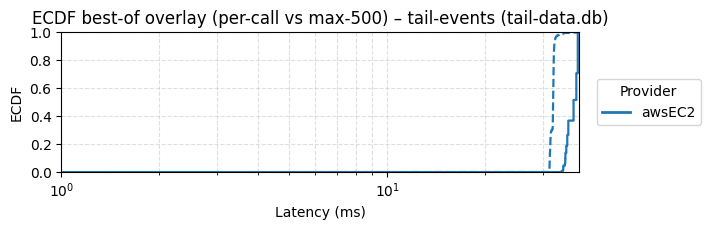

In [7]:
# Standalone max-of-N visualization (same style as cell 14: per-call vs max-of-500)
providers = [
    'awsEC2'
]
experiment = 'tail-events'
n_max = 500
samples_per_n = 4000
rng = np.random.default_rng(42)

x_min = 1
x_max = None
log_base = 10

palette = sns.color_palette('tab10', n_colors=len(providers))
fig, ax = plt.subplots(figsize=(7.2, 2.4))

providers_with_data = []
provider_colors = []

for provider, color in zip(providers, palette):
    lat = load_latencies_tail(provider, experiment)
    if lat.size == 0:
        continue

    providers_with_data.append(provider)
    provider_colors.append(color)

    sns.ecdfplot(lat, color=color, linestyle='--', linewidth=1.6, label=f'{provider} per-call', ax=ax)

    draws = rng.choice(lat, size=(samples_per_n, n_max), replace=True)
    max_samples = draws.max(axis=1)
    sns.ecdfplot(max_samples, color=color, linestyle='-', linewidth=1.6, label=f'{provider} max-{n_max}', ax=ax)

ax.set_title(f'ECDF best-of overlay (per-call vs max-{n_max}) – {experiment} (tail-data.db)')
ax.set_xlabel('Latency (ms)')
ax.set_ylabel('ECDF')
ax.set_xscale('log', base=log_base)
if x_min is not None or x_max is not None:
    ax.set_xlim(left=x_min, right=x_max)
ax.grid(True, which='both', linestyle='--', alpha=0.4)

if providers_with_data:
    legend_handles = [Line2D([0], [0], color=color, lw=2) for color in provider_colors]
    ax.legend(
        legend_handles,
        providers_with_data,
        title='Provider',
        loc='center left',
        bbox_to_anchor=(1.02, 0.5),
        frameon=True,
    )

fig.subplots_adjust(right=0.78)
fig.tight_layout()
plt.show()
plt.close(fig)

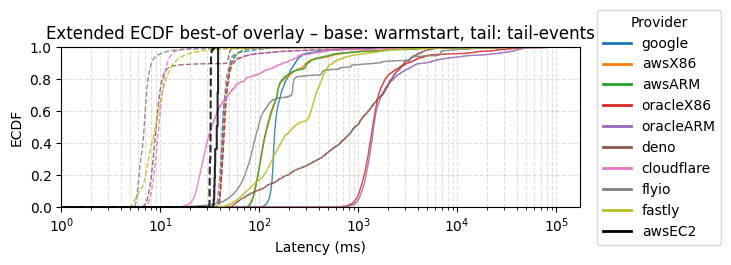

In [5]:
# Comparison extension: old providers (warmstart) + awsEC2 from tail-data.db on the same graph
providers = [
    'google', 'awsX86', 'awsARM', 'oracleX86', 'oracleARM',
    'deno', 'cloudflare', 'flyio', 'fastly'
]
experiment = 'warmstart'
tail_provider = 'awsEC2'
tail_experiment = 'tail-events'
n_max = 500
samples_per_n = 4000
rng = np.random.default_rng(42)

x_min = 1
x_max = None
log_base = 10

def load_latencies_base(provider: str, experiment: str) -> np.ndarray:
    if experiment == 'warmstart' and provider != 'fastly':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        '''
        params = [provider]
    elif experiment == 'warmstart' and provider == 'fastly':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        '''
        params = [provider]
    elif experiment == 'coldstart':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        '''
        params = [provider]
    else:
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = ?
        '''
        params = [provider, experiment]

    try:
        df = pd.read_sql_query(query, cnx_base, params=params)
    except Exception:
        return np.array([])
    return pd.to_numeric(df['http_req_waiting'], errors='coerce').dropna().values

def load_latencies_tail(provider: str, experiment: str) -> np.ndarray:
    query = '''
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = ?
    '''
    df = pd.read_sql_query(query, cnx_tail, params=[provider, experiment])
    return pd.to_numeric(df['http_req_waiting'], errors='coerce').dropna().values

palette = sns.color_palette('tab10', n_colors=len(providers))
fig, ax = plt.subplots(figsize=(7.4, 2.6))

legend_providers = []
legend_colors = []

# Existing data_copy providers (warmstart)
for provider, color in zip(providers, palette):
    lat = load_latencies_base(provider, experiment)
    if lat.size == 0:
        continue

    legend_providers.append(provider)
    legend_colors.append(color)

    sns.ecdfplot(lat, color=color, linestyle='--', linewidth=1.0, alpha=0.85, ax=ax)
    draws = rng.choice(lat, size=(samples_per_n, n_max), replace=True)
    max_samples = draws.max(axis=1)
    sns.ecdfplot(max_samples, color=color, linestyle='-', linewidth=1.0, alpha=0.85, ax=ax)

# awsEC2 from tail-data.db (tail-events)
lat_tail = load_latencies_tail(tail_provider, tail_experiment)
if lat_tail.size == 0:
    print(f'No data available in tail-data.db for {tail_provider} ({tail_experiment}).')
else:
    tail_color = 'black'
    legend_providers.append(tail_provider)
    legend_colors.append(tail_color)

    sns.ecdfplot(lat_tail, color=tail_color, linestyle='--', linewidth=1.5, alpha=0.85, ax=ax)
    draws_tail = rng.choice(lat_tail, size=(samples_per_n, n_max), replace=True)
    max_tail = draws_tail.max(axis=1)
    sns.ecdfplot(max_tail, color=tail_color, linestyle='-', linewidth=1.5, alpha=0.85, ax=ax)

ax.set_title(f'Extended ECDF best-of overlay – base: {experiment}, tail: {tail_experiment}')
ax.set_xlabel('Latency (ms)')
ax.set_ylabel('ECDF')
ax.set_xscale('log', base=log_base)
if x_min is not None or x_max is not None:
    ax.set_xlim(left=x_min, right=x_max)
ax.grid(True, which='both', linestyle='--', alpha=0.4)

if legend_providers:
    legend_handles = [Line2D([0], [0], color=color, lw=2) for color in legend_colors]
    ax.legend(
        legend_handles,
        legend_providers,
        title='Provider',
        loc='center left',
        bbox_to_anchor=(1.02, 0.5),
        frameon=True,
    )

fig.subplots_adjust(right=0.74)
fig.tight_layout()
plt.show()
plt.close(fig)

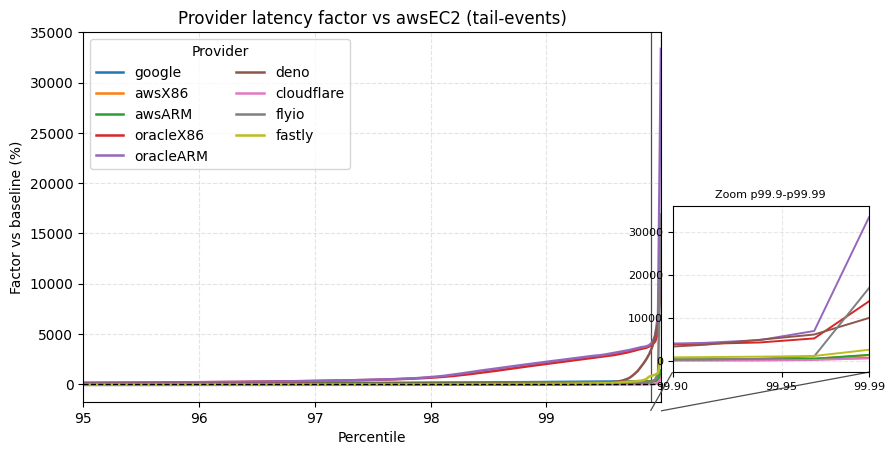

In [12]:
# Percentile-relative performance vs awsEC2 baseline
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

providers = [
    'google', 'awsX86', 'awsARM', 'oracleX86', 'oracleARM',
    'deno', 'cloudflare', 'flyio', 'fastly'
 ]
base_experiment = 'warmstart'
baseline_provider = 'awsEC2'
baseline_experiment = 'tail-events'

# Dense tail percentile grid for near-continuous curves (p95 to p100)
percentiles = np.linspace(0.95, 0.9999, 200)
x_percentiles = percentiles * 100.0

# Inset zoom configuration
show_zoom_inset = True
zoom_xmin = 99.9
zoom_xmax = 99.99

def load_latencies_base(provider: str, experiment: str) -> np.ndarray:
    if experiment == 'warmstart' and provider != 'fastly':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        '''
        params = [provider]
    elif experiment == 'warmstart' and provider == 'fastly':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        '''
        params = [provider]
    elif experiment == 'coldstart':
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'coldstart'
              AND cold_starts = 1
        '''
        params = [provider]
    else:
        query = '''
            SELECT http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = ?
        '''
        params = [provider, experiment]

    try:
        df = pd.read_sql_query(query, cnx_base, params=params)
    except Exception:
        return np.array([])
    return pd.to_numeric(df['http_req_waiting'], errors='coerce').dropna().values

def load_latencies_tail(provider: str, experiment: str) -> np.ndarray:
    query = '''
        SELECT http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = ?
    '''
    df = pd.read_sql_query(query, cnx_tail, params=[provider, experiment])
    return pd.to_numeric(df['http_req_waiting'], errors='coerce').dropna().values

baseline_lat = load_latencies_tail(baseline_provider, baseline_experiment)
if baseline_lat.size == 0:
    print(f'No baseline data for {baseline_provider} ({baseline_experiment}).')
else:
    baseline_q = np.quantile(baseline_lat, percentiles)

    palette = sns.color_palette('tab10', n_colors=len(providers))
    fig, ax = plt.subplots(figsize=(10.8, 4.8))

    plotted = 0
    plotted_series = []
    for provider, color in zip(providers, palette):
        lat = load_latencies_base(provider, base_experiment)
        if lat.size == 0:
            print(f'No data for provider {provider} ({base_experiment}).')
            continue

        provider_q = np.quantile(lat, percentiles)
        # Signed percent difference vs baseline: negative = faster, positive = slower
        factor_pct = ((provider_q - baseline_q) / baseline_q) * 100.0

        ax.plot(x_percentiles, factor_pct, linewidth=1.8, color=color, label=provider)
        plotted_series.append((provider, color, factor_pct))
        plotted += 1

    ax.axhline(0.0, color='black', linestyle='--', linewidth=1.0)
    ax.set_title(f'Provider latency factor vs {baseline_provider} ({baseline_experiment})')
    ax.set_xlabel('Percentile')
    ax.set_ylabel('Factor vs baseline (%)')
    ax.set_xlim(95.0, 99.99)
    ax.grid(True, linestyle='--', alpha=0.35)

    if plotted > 0:
        ax.legend(title='Provider', ncol=2, frameon=True)

    if show_zoom_inset and plotted_series:
        axins = inset_axes(
            ax,
            width='34%',
            height='45%',
            loc='lower left',
            bbox_to_anchor=(1.02, 0.08, 1.0, 1.0),
            bbox_transform=ax.transAxes,
            borderpad=0.0,
        )

        zoom_values = []
        mask = (x_percentiles >= zoom_xmin) & (x_percentiles <= zoom_xmax)
        for _, color, series in plotted_series:
            axins.plot(x_percentiles, series, linewidth=1.4, color=color)
            zoom_values.extend(series[mask])

        axins.set_xlim(zoom_xmin, zoom_xmax)
        zoom_values = np.asarray(zoom_values, dtype=float)
        zoom_values = zoom_values[np.isfinite(zoom_values)]
        if zoom_values.size:
            y_span = float(zoom_values.max() - zoom_values.min())
            y_pad = 0.08 * y_span if y_span > 0 else 0.5
            axins.set_ylim(float(zoom_values.min() - y_pad), float(zoom_values.max() + y_pad))

        axins.set_xticks([99.9, 99.95, 99.99])
        axins.tick_params(axis='both', labelsize=8)
        axins.grid(True, linestyle='--', alpha=0.3)
        axins.set_title('Zoom p99.9-p99.99', fontsize=8)

        mark_inset(ax, axins, loc1=3, loc2=4, fc='none', ec='0.3', lw=0.9)

    fig.subplots_adjust(right=0.66)
    plt.show()
    plt.close(fig)